# COMP4318/5318 Assignment 2: Image Classification

**Execution environment:** Install `A2/requirements.txt` in a Python 3.10 environment and select its Jupyter kernel. On this computer, use `A2 CNN (Python 3.10)`. Run the cells from top to bottom; the final CNN training cell can also run when the tuning cell is skipped.

### Group number: 217  , SID1: STUDENT_ID_REDACTED , SID2: ..., SID3: ..., SID4: ...

This template notebook includes code to load the  dataset and a skeleton for the main sections that should be included in the notebook. Please stick to this struture for your submitted notebook.

Please focus on making your code clear, with appropriate variable names and whitespace. Include comments and markdown text to aid the readability of your code where relevant. See the specification and marking criteria in the associated specification to guide you when completing your implementation.

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment.

In [1]:
# Import libraries for data handling, visualisation, splitting, and evaluation
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

# Set a fixed random seed so that the validation split and experiments are reproducible
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Use a consistent plotting style throughout the notebook
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Data loading, exploration, and preprocessing

Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [2]:
# Load the dataset training and test sets as numpy arrays
# assuming Assignment2Data folder is present in the same directory 
# as the notebook
X_train = np.load('Assignment2Data/X_train.npy')
y_train = np.load('Assignment2Data/y_train.npy')
X_test = np.load('Assignment2Data/X_test.npy')
y_test = np.load('Assignment2Data/y_test.npy')

### 1.1 Data validation and summary

Before preprocessing, we verify the relationship between the images and labels, inspect the array shapes and data types, and confirm the expected image and class structure. These checks detect path, shape, or label errors before any model is trained.

In [3]:
# Keep explicit references to the unmodified uint8 arrays
X_train_raw = X_train
y_train_raw = y_train
X_test_raw = X_test
y_test_raw = y_test

# Validate that each image has exactly one corresponding label
assert X_train_raw.shape[0] == y_train_raw.shape[0], "Training images and labels do not match."
assert X_test_raw.shape[0] == y_test_raw.shape[0], "Test images and labels do not match."

# Validate the expected 28 x 28 RGB image format and integer labels

assert X_train_raw.shape[1:] == (28, 28, 3), "Unexpected training image shape."
assert X_test_raw.shape[1:] == (28, 28, 3), "Unexpected test image shape."
assert y_train_raw.ndim == 1 and y_test_raw.ndim == 1, "Labels must be one-dimensional."

train_classes = np.unique(y_train_raw)
test_classes = np.unique(y_test_raw)

# The supplied training and test sets should contain the same nine classes
assert np.array_equal(train_classes, test_classes), "Training and test classes do not match."
assert np.array_equal(train_classes, np.arange(9)), "Expected class labels 0 to 8."

dataset_summary = pd.DataFrame(
    {
        "Split": ["Training", "Test"],
        "Samples": [len(X_train_raw), len(X_test_raw)],
        "Image shape": [str(X_train_raw.shape[1:]), str(X_test_raw.shape[1:])],
        "Image dtype": [str(X_train_raw.dtype), str(X_test_raw.dtype)],
        "Pixel minimum": [X_train_raw.min(), X_test_raw.min()],
        "Pixel maximum": [X_train_raw.max(), X_test_raw.max()],
        "Number of classes": [len(train_classes), len(test_classes)],
    }
)

display(dataset_summary)
print("Class labels:", train_classes)
print("Dataset validation completed successfully.")

,Split,Samples,Image shape,Image dtype,Pixel minimum,Pixel maximum,Number of classes
0,Training,32000,"(28, 28, 3)",uint8,0,255,9
1,Test,8000,"(28, 28, 3)",uint8,0,255,9


Class labels: [0 1 2 3 4 5 6 7 8]
Dataset validation completed successfully.


### 1.2 Class distribution

Class counts and proportions are inspected separately for the supplied training and test sets. This identifies class imbalance and checks whether accuracy alone will be sufficient for evaluation. The supplied test set is inspected descriptively here but is not used to choose preprocessing settings, architectures, or hyperparameters.

,Split,Class ID,Class name,Count,Proportion
0,Training,0,Adipose,3490,0.109063
1,Training,1,Background,3431,0.107219
2,Training,2,Debris,3505,0.109531
3,Training,3,Lymphocytes,3656,0.114250
4,Training,4,Mucus,2950,0.092188
5,Training,5,Smooth muscle,4290,0.134063
6,Training,6,Normal colon mucosa,2728,0.085250
7,Training,7,Cancer-associated stroma,3253,0.101656
8,Training,8,Colorectal adenocarcinoma epithelium,4697,0.146781
9,Test,0,Adipose,873,0.109125


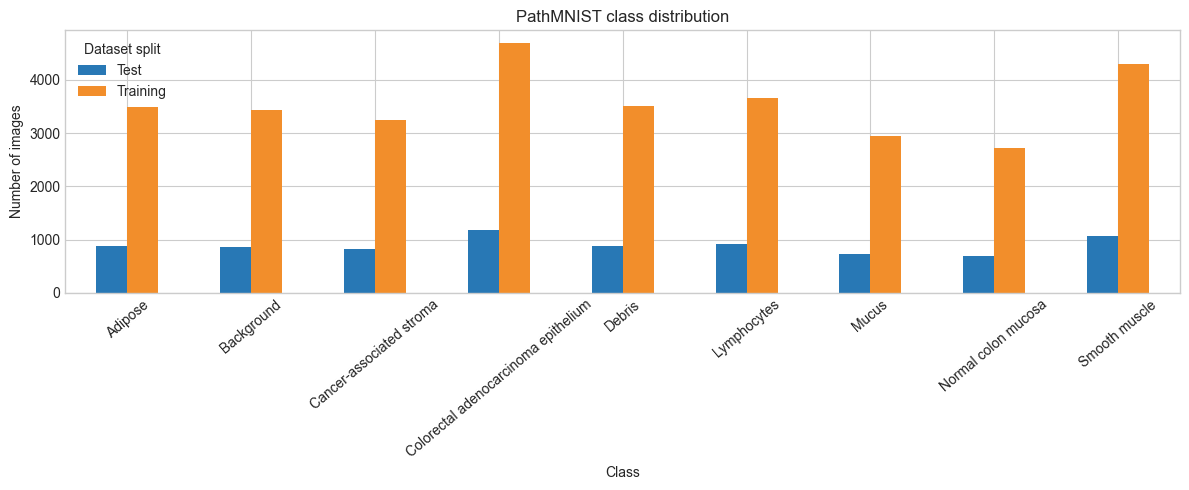

In [4]:
# PathMNIST class names corresponding to labels 0-8
CLASS_NAMES = {
    0: "Adipose",
    1: "Background",
    2: "Debris",
    3: "Lymphocytes",
    4: "Mucus",
    5: "Smooth muscle",
    6: "Normal colon mucosa",
    7: "Cancer-associated stroma",
    8: "Colorectal adenocarcinoma epithelium",
}

def build_class_distribution(labels, split_name):
    # Return class counts and proportions for one dataset split.
    class_ids, counts = np.unique(labels, return_counts=True)
    return pd.DataFrame(
        {
            "Split": split_name,
            "Class ID": class_ids,
            "Class name": [CLASS_NAMES[class_id] for class_id in class_ids],
            "Count": counts,
            "Proportion": counts / len(labels),
        }
    )

class_distribution = pd.concat(
    [
        build_class_distribution(y_train_raw, "Training"),
        build_class_distribution(y_test_raw, "Test"),
    ],
    ignore_index=True,
)

display(class_distribution)

# Plot training and test counts side by side for an immediate imbalance check
distribution_pivot = class_distribution.pivot(
    index="Class name", columns="Split", values="Count"
)
ax = distribution_pivot.plot(kind="bar", figsize=(12, 5), color=["#2878B5", "#F28E2B"])
ax.set_title("PathMNIST class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Dataset split")
plt.tight_layout()
plt.show()

### 1.3 Visual exploration of the images

One reproducibly selected image from each class is displayed to inspect colour, texture, centring, and visual similarities between tissue categories. Mean images are also shown to reveal class-level colour and structural tendencies that may not be obvious from individual samples.

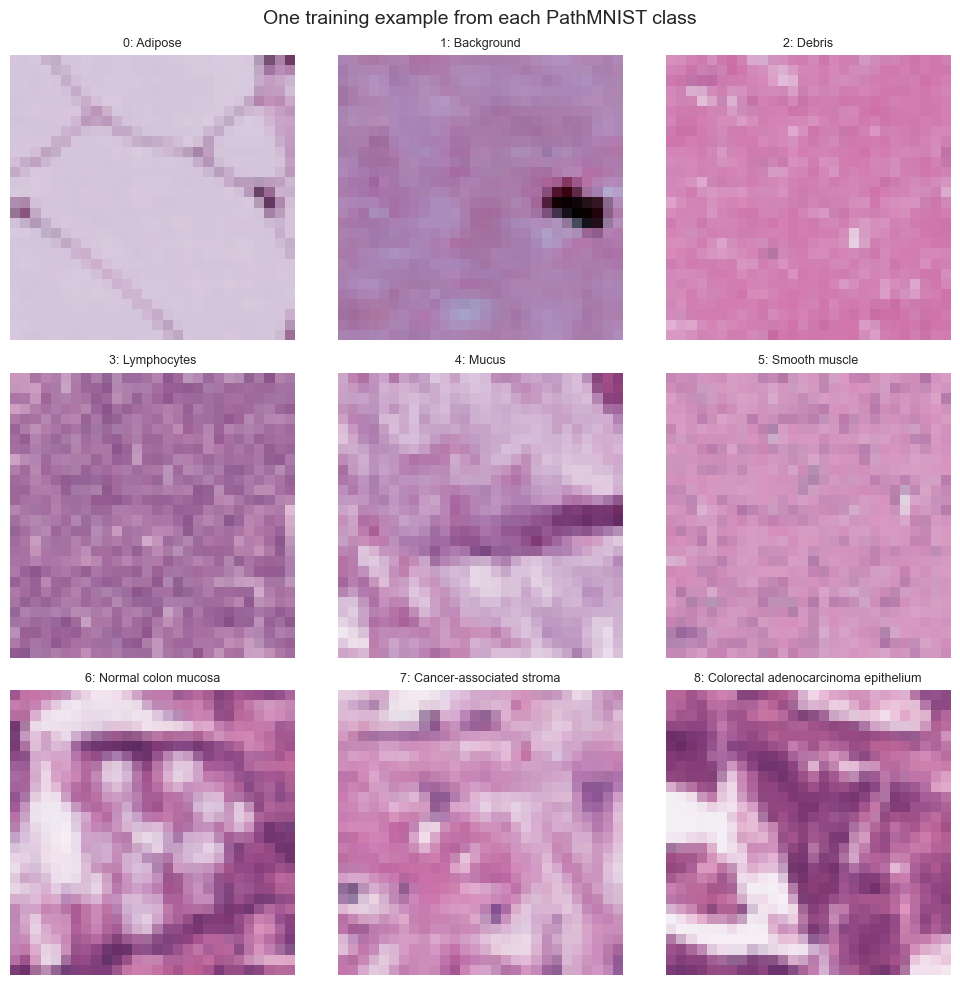

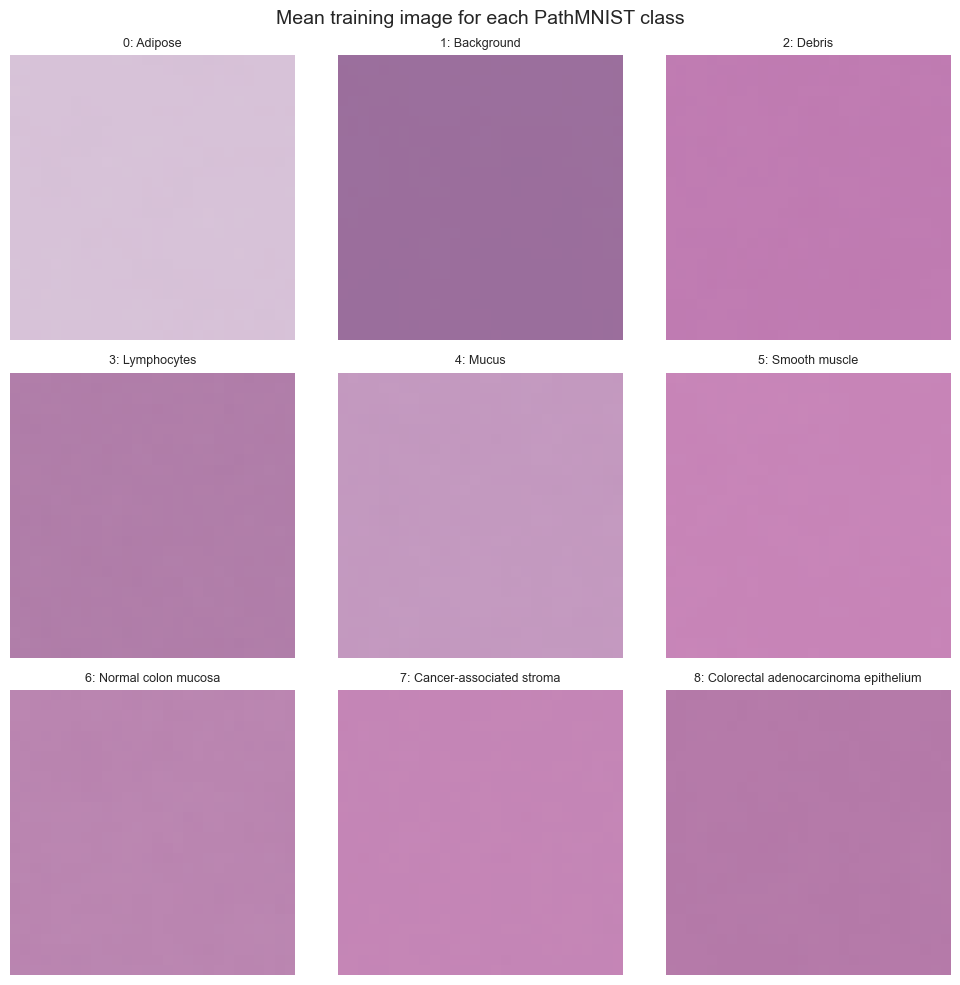

In [5]:
# Use a dedicated generator so image selection is reproducible without changing other experiments
sample_rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for class_id, ax in zip(train_classes, axes.flat):
    class_indices = np.flatnonzero(y_train_raw == class_id)
    sample_index = sample_rng.choice(class_indices)
    ax.imshow(X_train_raw[sample_index])
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}", fontsize=9)
    ax.axis("off")

fig.suptitle("One training example from each PathMNIST class", fontsize=14)
plt.tight_layout()
plt.show()

# Average all images within each class to expose broad colour and structural patterns
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for class_id, ax in zip(train_classes, axes.flat):
    mean_image = X_train_raw[y_train_raw == class_id].mean(axis=0).astype(np.uint8)
    ax.imshow(mean_image)
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}", fontsize=9)
    ax.axis("off")

fig.suptitle("Mean training image for each PathMNIST class", fontsize=14)
plt.tight_layout()
plt.show()

### 1.4 Pixel-intensity exploration

Global and channel-wise statistics are calculated to determine the numeric scale and colour characteristics of the images. A subsample is used for the histogram to keep plotting efficient while retaining a representative view of the intensity distribution.

,Channel,Mean,Standard deviation,Minimum,Maximum
0,Red,188.65,31.91,0,255
1,Green,135.93,45.60,0,252
2,Blue,180.05,32.18,0,255


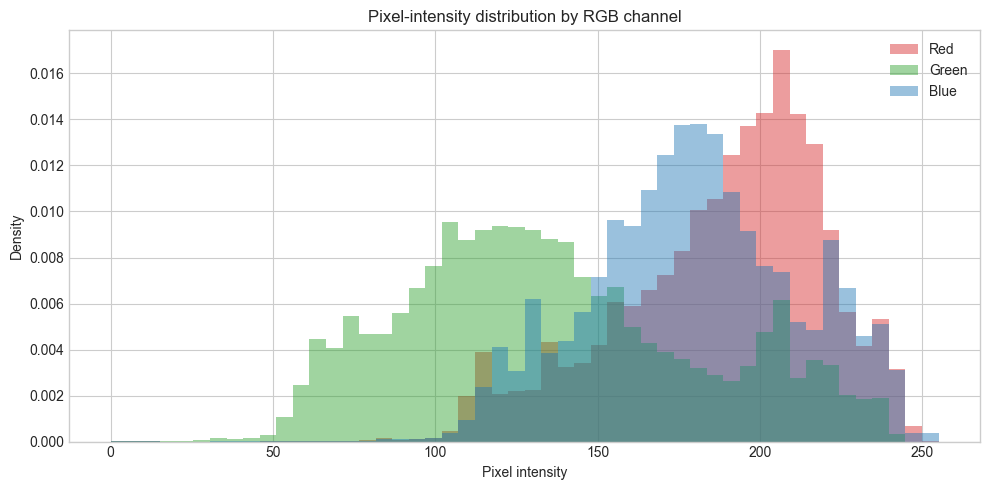

,Class ID,Class name,Mean intensity,Intensity standard deviation
0,0,Adipose,208.67,26.35
1,1,Background,140.97,55.89
2,2,Debris,164.57,41.09
3,3,Lymphocytes,157.37,36.42
4,4,Mucus,180.28,34.59
5,5,Smooth muscle,172.24,40.23
6,6,Normal colon mucosa,165.66,41.93
7,7,Cancer-associated stroma,171.08,34.98
8,8,Colorectal adenocarcinoma epithelium,157.46,41.72


In [6]:
# Compute channel statistics across all training images and spatial positions
channel_names = ["Red", "Green", "Blue"]
channel_statistics = pd.DataFrame(
    {
        "Channel": channel_names,
        "Mean": X_train_raw.mean(axis=(0, 1, 2)),
        "Standard deviation": X_train_raw.std(axis=(0, 1, 2)),
        "Minimum": X_train_raw.min(axis=(0, 1, 2)),
        "Maximum": X_train_raw.max(axis=(0, 1, 2)),
    }
)
display(channel_statistics.round(2))

# Sample every twentieth image to make histogram calculation memory-efficient
pixel_sample = X_train_raw[::20]
channel_colours = ["#D62728", "#2CA02C", "#1F77B4"]

fig, ax = plt.subplots(figsize=(10, 5))
for channel_index, (channel_name, colour) in enumerate(zip(channel_names, channel_colours)):
    ax.hist(
        pixel_sample[..., channel_index].ravel(),
        bins=50,
        range=(0, 255),
        density=True,
        alpha=0.45,
        color=colour,
        label=channel_name,
    )

ax.set_title("Pixel-intensity distribution by RGB channel")
ax.set_xlabel("Pixel intensity")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

# Compare average image intensity across classes as a compact numerical summary
class_intensity_summary = pd.DataFrame(
    {
        "Class ID": train_classes,
        "Class name": [CLASS_NAMES[class_id] for class_id in train_classes],
        "Mean intensity": [
            X_train_raw[y_train_raw == class_id].mean() for class_id in train_classes
        ],
        "Intensity standard deviation": [
            X_train_raw[y_train_raw == class_id].std() for class_id in train_classes
        ],
    }
)
display(class_intensity_summary.round(2))

### 1.5 Preprocessing and stratified validation split

The supplied test set is reserved exclusively for the final comparison. A validation set is therefore created only from the supplied training data. Stratification preserves the class proportions in both subsets. Pixel values are converted from unsigned 8-bit integers in `[0, 255]` to `float32` values in `[0, 1]`, which gives neural-network optimisation a stable numeric scale and supplies a consistent representation to all models.

Two representations are prepared without altering the source arrays:

- `*_images`: shape `(n, 28, 28, 3)` for the CNN.
- `*_flat`: shape `(n, 2352)` for the first-six-weeks classifier and MLP.

In [7]:
# Reserve 20% of the supplied training data for validation
VALIDATION_SIZE = 0.20
all_training_indices = np.arange(len(X_train_raw))

train_indices, validation_indices = train_test_split(
    all_training_indices,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train_raw,
)

# Split first, then convert and normalise each subset to avoid modifying the source arrays
X_train_images = X_train_raw[train_indices].astype(np.float32) / 255.0
X_validation_images = X_train_raw[validation_indices].astype(np.float32) / 255.0
X_test_images = X_test_raw.astype(np.float32) / 255.0

y_train_split = y_train_raw[train_indices].astype(np.int64)
y_validation = y_train_raw[validation_indices].astype(np.int64)
y_test_final = y_test_raw.astype(np.int64)

# Flattening creates model-ready feature matrices while retaining the same samples
X_train_flat = X_train_images.reshape(len(X_train_images), -1)
X_validation_flat = X_validation_images.reshape(len(X_validation_images), -1)
X_test_flat = X_test_images.reshape(len(X_test_images), -1)

# Confirm that preprocessing produced the intended ranges and shapes
assert 0.0 <= X_train_images.min() <= X_train_images.max() <= 1.0
assert 0.0 <= X_validation_images.min() <= X_validation_images.max() <= 1.0
assert 0.0 <= X_test_images.min() <= X_test_images.max() <= 1.0
assert X_train_flat.shape[1] == 28 * 28 * 3
assert X_validation_flat.shape[1] == 28 * 28 * 3
assert X_test_flat.shape[1] == 28 * 28 * 3

preprocessing_summary = pd.DataFrame(
    {
        "Subset": ["Training", "Validation", "Test"],
        "Samples": [len(y_train_split), len(y_validation), len(y_test_final)],
        "Image input shape": [
            str(X_train_images.shape),
            str(X_validation_images.shape),
            str(X_test_images.shape),
        ],
        "Flattened input shape": [
            str(X_train_flat.shape),
            str(X_validation_flat.shape),
            str(X_test_flat.shape),
        ],
        "Minimum": [
            X_train_images.min(),
            X_validation_images.min(),
            X_test_images.min(),
        ],
        "Maximum": [
            X_train_images.max(),
            X_validation_images.max(),
            X_test_images.max(),
        ],
    }
)
display(preprocessing_summary)

# Check that stratification kept class proportions nearly unchanged
split_distribution = pd.concat(
    [
        build_class_distribution(y_train_split, "Training split"),
        build_class_distribution(y_validation, "Validation split"),
    ],
    ignore_index=True,
)
display(
    split_distribution.pivot(
        index=["Class ID", "Class name"],
        columns="Split",
        values="Proportion",
    ).round(4)
)

print("Preprocessing and stratified validation split completed successfully.")

,Subset,Samples,Image input shape,Flattened input shape,Minimum,Maximum
0,Training,25600,"(25600, 28, 28, 3)","(25600, 2352)",0.0,1.0
1,Validation,6400,"(6400, 28, 28, 3)","(6400, 2352)",0.0,1.0
2,Test,8000,"(8000, 28, 28, 3)","(8000, 2352)",0.0,1.0


,Split,Training split,Validation split
Class ID,Class name,,
0,Adipose,0.1091,0.1091
1,Background,0.1072,0.1072
2,Debris,0.1095,0.1095
3,Lymphocytes,0.1143,0.1142
4,Mucus,0.0922,0.0922
5,Smooth muscle,0.1341,0.1341
6,Normal colon mucosa,0.0852,0.0853
7,Cancer-associated stroma,0.1016,0.1017
8,Colorectal adenocarcinoma epithelium,0.1468,0.1467


Preprocessing and stratified validation split completed successfully.


### Examples of preprocessed data

The comparison below verifies that normalisation changes the numeric scale but does not alter the visual content. The original image is stored as `uint8` in `[0, 255]`, while the model-ready image is stored as `float32` in `[0, 1]`.

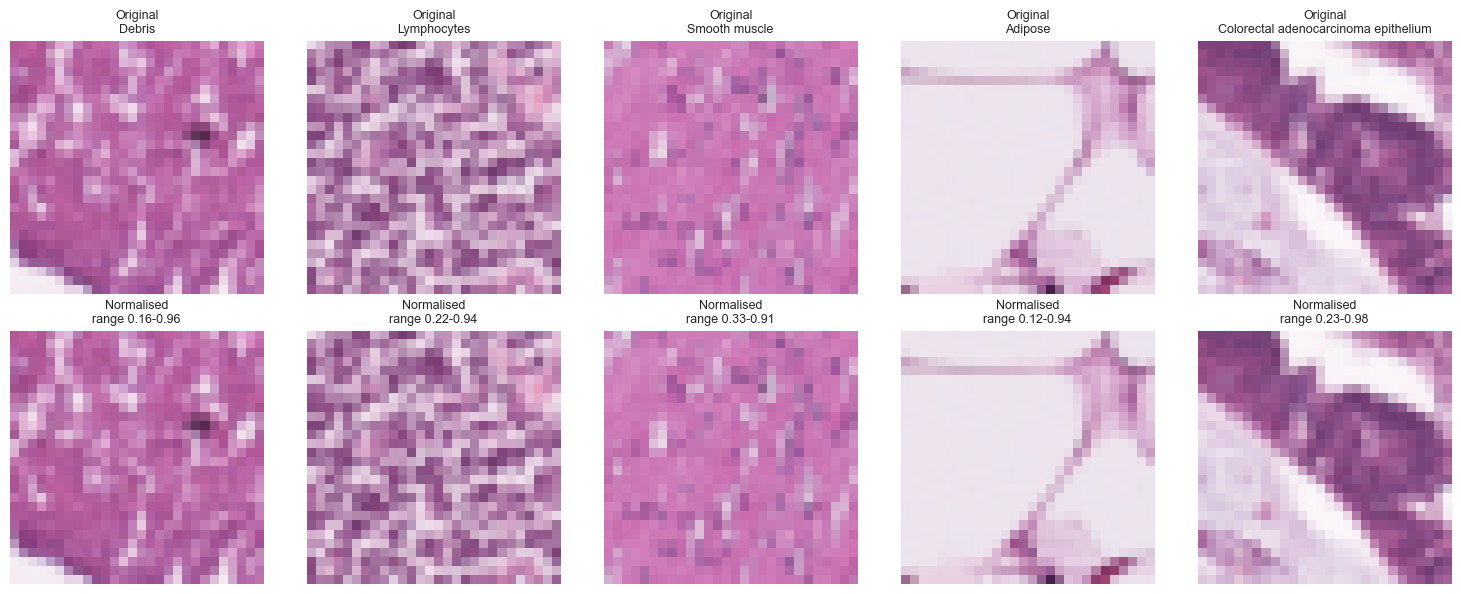

In [8]:
# Compare the original and normalised versions of the same training examples
example_indices = train_indices[:5]
fig, axes = plt.subplots(2, len(example_indices), figsize=(15, 6))

for column, original_index in enumerate(example_indices):
    axes[0, column].imshow(X_train_raw[original_index])
    axes[0, column].set_title(
        f"Original\n{CLASS_NAMES[int(y_train_raw[original_index])]}", fontsize=9
    )
    axes[0, column].axis("off")

    axes[1, column].imshow(X_train_images[column])
    axes[1, column].set_title(
        f"Normalised\nrange {X_train_images[column].min():.2f}-{X_train_images[column].max():.2f}",
        fontsize=9,
    )
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

### 1.6 Shared evaluation utilities

The functions below give all three models a consistent evaluation procedure. They report accuracy and macro-averaged precision, recall, and F1-score, then display a per-class classification report and confusion matrix. Macro averages give every tissue class equal importance, which is useful when class frequencies differ. Prediction runtime is measured separately from training runtime.

In [9]:
def convert_predictions_to_labels(predictions):
    """Convert class probabilities or class IDs into a one-dimensional label array."""
    predictions = np.asarray(predictions)
    if predictions.ndim == 2:
        return np.argmax(predictions, axis=1)
    return predictions.astype(np.int64).ravel()

def evaluate_predictions(y_true, predictions, model_name, prediction_time=None):
    """Calculate metrics and plot a confusion matrix for one model."""
    y_pred = convert_predictions_to_labels(predictions)
    labels = np.arange(len(CLASS_NAMES))

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": precision_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Prediction time (s)": prediction_time,
    }

    display(pd.DataFrame([metrics]).round(4))
    print(
        classification_report(
            y_true,
            y_pred,
            labels=labels,
            target_names=[CLASS_NAMES[label] for label in labels],
            digits=4,
            zero_division=0,
        )
    )

    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    display_labels = [f"{label}: {CLASS_NAMES[label]}" for label in labels]
    figure, axis = plt.subplots(figsize=(11, 9))
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=display_labels,
    ).plot(ax=axis, cmap="Blues", values_format="d", colorbar=False)
    axis.set_title(f"Confusion matrix: {model_name}")
    axis.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

    return metrics, y_pred

def predict_and_evaluate(model, X_evaluation, y_evaluation, model_name, **predict_kwargs):
    """Time model prediction and apply the shared evaluation procedure."""
    start_time = perf_counter()
    predictions = model.predict(X_evaluation, **predict_kwargs)
    prediction_time = perf_counter() - start_time
    return evaluate_predictions(
        y_evaluation,
        predictions,
        model_name=model_name,
        prediction_time=prediction_time,
    )

def plot_training_history(history, model_name):
    """Plot training and validation accuracy and loss from a Keras History object."""
    history_values = history.history
    epochs = np.arange(1, len(history_values["loss"]) + 1)

    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history_values["accuracy"], label="Training")
    axes[0].plot(epochs, history_values["val_accuracy"], label="Validation")
    axes[0].set_title(f"{model_name}: accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(epochs, history_values["loss"], label="Training")
    axes[1].plot(epochs, history_values["val_loss"], label="Validation")
    axes[1].set_title(f"{model_name}: loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

> **Data-leakage control**
> The validation split is used for model design and hyperparameter selection. The supplied test set must remain untouched until each final model has been fixed and independently trained. Test performance must not be used to revise hyperparameters.
>

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

The CNN receives the shared 28×28 RGB arrays without flattening them. Small 3×3 filters reuse the same weights across image locations to detect local colour and texture patterns; pooling halves the spatial size after each convolution. A 64-unit dense layer combines the learned features, dropout regularises it, and softmax produces nine class probabilities. The labels are integer class IDs, so sparse categorical cross-entropy is the appropriate loss. The builder exposes filter count, dropout rate, and learning rate for the search below.

In [10]:
from tensorflow import keras

keras.utils.set_random_seed(RANDOM_STATE)

def build_cnn(base_filters=16, dropout_rate=0.25, learning_rate=1e-3):
    """Build and compile a small CNN for 28x28 RGB PathMNIST images."""
    model = keras.Sequential(
        [
            keras.Input(shape=(28, 28, 3)),
            keras.layers.Conv2D(base_filters, 3, padding="same", activation="relu"),
            keras.layers.MaxPooling2D(pool_size=2),
            keras.layers.Conv2D(base_filters * 2, 3, padding="same", activation="relu"),
            keras.layers.MaxPooling2D(pool_size=2),
            keras.layers.Flatten(),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dropout(dropout_rate),
            keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
        ],
        name="pathmnist_cnn",
    )
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    return model

cnn_baseline = build_cnn()
assert cnn_baseline.input_shape[1:] == X_train_images.shape[1:]
assert cnn_baseline.output_shape[-1] == len(CLASS_NAMES)
cnn_baseline.summary()

Model: "pathmnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,089 (414.41 KB)

 Trainable params: 106,089 (414.41 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Hyperparameter tuning

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

We compare eight combinations: 16 or 32 filters in the first convolution, dropout of 0.2 or 0.4, and Adam learning rates of 0.001 or 0.0003. These control model capacity, regularisation, and optimisation speed. To bound CPU runtime, every candidate trains on the same stratified 6,000-image subset of the training split; each is scored on the entire 6,400-image validation split. Early stopping restores the weights with lowest validation loss. We rank candidates by validation macro-F1, with accuracy as a tie-breaker, because class frequencies differ. The supplied test set is not used in this search. The table records every combination, its score, epochs, parameter count, and runtime; keep its output in the submitted notebook.

In [11]:
from itertools import product

CNN_SEARCH_TRAIN_SIZE = 6000
CNN_SEARCH_EPOCHS = 5
CNN_BATCH_SIZE = 64

# Use one fixed stratified subset for every candidate, so scores are comparable.
cnn_search_indices, _ = train_test_split(
    np.arange(len(y_train_split)),
    train_size=CNN_SEARCH_TRAIN_SIZE,
    stratify=y_train_split,
    random_state=RANDOM_STATE,
)
X_cnn_search = X_train_images[cnn_search_indices]
y_cnn_search = y_train_split[cnn_search_indices]

cnn_search_configs = [
    dict(base_filters=filters, dropout_rate=dropout, learning_rate=rate)
    for filters, dropout, rate in product([16, 32], [0.2, 0.4], [1e-3, 3e-4])
]
cnn_search_rows = []

for config in cnn_search_configs:
    keras.backend.clear_session()
    keras.utils.set_random_seed(RANDOM_STATE)
    candidate = build_cnn(**config)
    started = perf_counter()
    history = candidate.fit(
        X_cnn_search,
        y_cnn_search,
        validation_data=(X_validation_images, y_validation),
        epochs=CNN_SEARCH_EPOCHS,
        batch_size=CNN_BATCH_SIZE,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=2, restore_best_weights=True
            )
        ],
        verbose=0,
    )
    training_seconds = perf_counter() - started
    started = perf_counter()
    probabilities = candidate.predict(X_validation_images, batch_size=256, verbose=0)
    prediction_seconds = perf_counter() - started
    predicted_labels = convert_predictions_to_labels(probabilities)
    result = {
        **config,
        "validation_accuracy": accuracy_score(y_validation, predicted_labels),
        "validation_macro_f1": f1_score(
            y_validation, predicted_labels, average="macro", zero_division=0
        ),
        "epochs_run": len(history.history["loss"]),
        "parameter_count": candidate.count_params(),
        "training_seconds": training_seconds,
        "prediction_seconds": prediction_seconds,
    }
    cnn_search_rows.append(result)
    print(config, "macro-F1:", round(result["validation_macro_f1"], 4),
          "training seconds:", round(training_seconds, 1))
    del candidate

cnn_search_results = pd.DataFrame(cnn_search_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False
).reset_index(drop=True)
display(cnn_search_results.round(4))

{'base_filters': 16, 'dropout_rate': 0.2, 'learning_rate': 0.001} macro-F1: 0.5285 training seconds: 3.3


{'base_filters': 16, 'dropout_rate': 0.2, 'learning_rate': 0.0003} macro-F1: 0.4595 training seconds: 3.2


{'base_filters': 16, 'dropout_rate': 0.4, 'learning_rate': 0.001} macro-F1: 0.5027 training seconds: 3.2


{'base_filters': 16, 'dropout_rate': 0.4, 'learning_rate': 0.0003} macro-F1: 0.4008 training seconds: 3.2


{'base_filters': 32, 'dropout_rate': 0.2, 'learning_rate': 0.001} macro-F1: 0.5395 training seconds: 4.5


{'base_filters': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0003} macro-F1: 0.4333 training seconds: 4.5


{'base_filters': 32, 'dropout_rate': 0.4, 'learning_rate': 0.001} macro-F1: 0.508 training seconds: 4.6


{'base_filters': 32, 'dropout_rate': 0.4, 'learning_rate': 0.0003} macro-F1: 0.4237 training seconds: 4.9


,base_filters,dropout_rate,learning_rate,validation_accuracy,validation_macro_f1,epochs_run,parameter_count,training_seconds,prediction_seconds
0,32,0.2,0.0010,0.5711,0.5395,5,220745,4.4597,0.2238
1,16,0.2,0.0010,0.5708,0.5285,5,106089,3.2553,0.1734
2,32,0.4,0.0010,0.5409,0.5080,5,220745,4.6267,0.2572
3,16,0.4,0.0010,0.5459,0.5027,5,106089,3.2394,0.1663
4,16,0.2,0.0003,0.5319,0.4595,5,106089,3.2297,0.1588
5,32,0.2,0.0003,0.5041,0.4333,5,220745,4.4887,0.2434
6,32,0.4,0.0003,0.4986,0.4237,5,220745,4.8501,0.2359
7,16,0.4,0.0003,0.4989,0.4008,5,106089,3.1780,0.1611


## 4. Final models
In this section, please ensure to include cells to train each model with its best hyperparmater combination independently of the hyperparameter tuning cells, i.e. don't rely on the hyperparameter tuning cells having been run.

### Algorithm of choice from first six weeks of course

### Fully connected neural network

### Convolutional neural network

The eight-trial search selected 32 first-layer filters, dropout 0.2, and learning rate 0.001 (validation macro-F1 0.5395 on the fixed 6,000-image search training subset). These values are written explicitly below. This cell rebuilds the CNN from scratch and trains on the full 25,600-image training split, so it runs even when the search cell is skipped. Early stopping uses only the validation split. Only after the architecture and hyperparameters are fixed do we evaluate once on the supplied test set.

Epoch 1/12


400/400 - 3s - 8ms/step - accuracy: 0.3930 - loss: 1.6138 - val_accuracy: 0.5136 - val_loss: 1.2299


Epoch 2/12


400/400 - 2s - 6ms/step - accuracy: 0.5455 - loss: 1.2113 - val_accuracy: 0.6094 - val_loss: 1.0575


Epoch 3/12


400/400 - 2s - 6ms/step - accuracy: 0.6087 - loss: 1.0456 - val_accuracy: 0.6725 - val_loss: 0.9074


... (11 outputs left out)

400/400 - 3s - 7ms/step - accuracy: 0.7326 - loss: 0.7350 - val_accuracy: 0.7159 - val_loss: 0.7743


Epoch 10/12


400/400 - 2s - 6ms/step - accuracy: 0.7395 - loss: 0.7119 - val_accuracy: 0.7581 - val_loss: 0.6923


Selected CNN hyperparameters: {'base_filters': 32, 'dropout_rate': 0.2, 'learning_rate': 0.001}
Training seconds: 25.5
Epochs run: 10


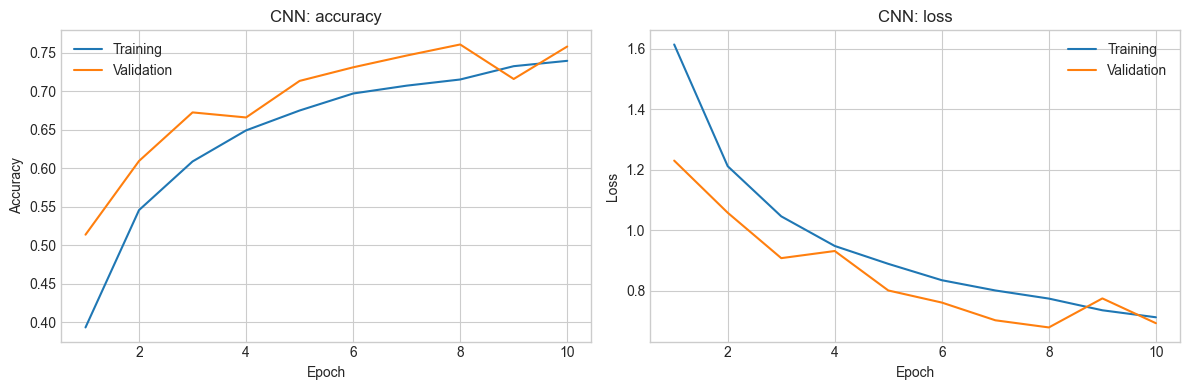

In [12]:
# Literal values keep final training independent of the search cell.
CNN_FINAL_CONFIG = dict(base_filters=32, dropout_rate=0.2, learning_rate=1e-3)
CNN_FINAL_EPOCHS = 12
CNN_FINAL_BATCH_SIZE = 64

keras.backend.clear_session()
keras.utils.set_random_seed(RANDOM_STATE)
cnn_final = build_cnn(**CNN_FINAL_CONFIG)
started = perf_counter()
cnn_final_history = cnn_final.fit(
    X_train_images,
    y_train_split,
    validation_data=(X_validation_images, y_validation),
    epochs=CNN_FINAL_EPOCHS,
    batch_size=CNN_FINAL_BATCH_SIZE,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )
    ],
    verbose=2,
)
cnn_final_training_seconds = perf_counter() - started
print("Selected CNN hyperparameters:", CNN_FINAL_CONFIG)
print("Training seconds:", round(cnn_final_training_seconds, 1))
print("Epochs run:", len(cnn_final_history.history["loss"]))
plot_training_history(cnn_final_history, "CNN")

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Prediction time (s)
0,CNN,0.7542,0.7462,0.7463,0.7436,0.3146


                                      precision    recall  f1-score   support

                             Adipose     0.8789    0.9805    0.9269       873
                          Background     0.9886    0.9114    0.9485       858
                              Debris     0.5607    0.5428    0.5516       877
                         Lymphocytes     0.8458    0.9661    0.9019       914
                               Mucus     0.7716    0.7015    0.7349       737
                       Smooth muscle     0.7437    0.6875    0.7145      1072
                 Normal colon mucosa     0.6154    0.6452    0.6299       682
            Cancer-associated stroma     0.5787    0.4477    0.5049       813
Colorectal adenocarcinoma epithelium     0.7322    0.8339    0.7798      1174

                            accuracy                         0.7542      8000
                           macro avg     0.7462    0.7463    0.7436      8000
                        weighted avg     0.7495    0.7542    0

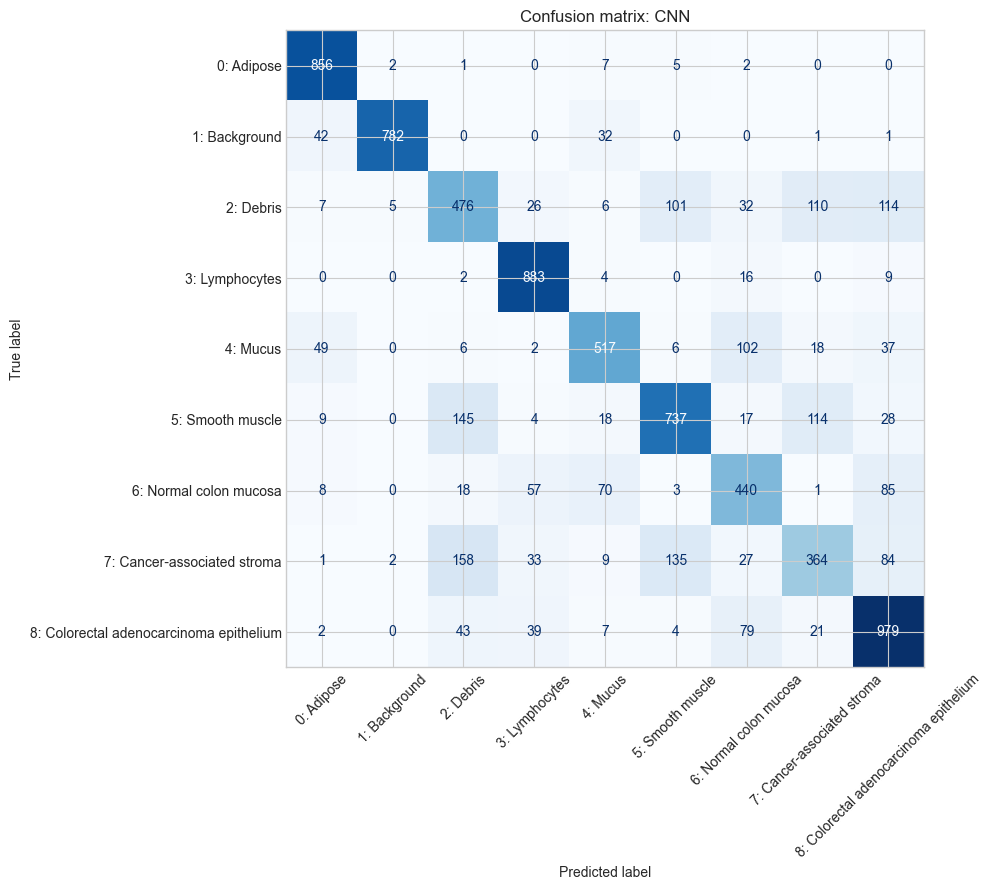

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Prediction time (s),Training time (s),Epochs run
0,CNN,0.7542,0.7462,0.7463,0.7436,0.3146,25.4901,10


In [13]:
# The supplied test labels enter the CNN workflow only here.
cnn_test_metrics, cnn_test_predictions = predict_and_evaluate(
    cnn_final,
    X_test_images,
    y_test_final,
    model_name="CNN",
    batch_size=256,
    verbose=0,
)
cnn_test_metrics["Training time (s)"] = cnn_final_training_seconds
cnn_test_metrics["Epochs run"] = len(cnn_final_history.history["loss"])
display(pd.DataFrame([cnn_test_metrics]).round(4))

### CNN results and interpretation

The eight search trials compared convolution filter counts, dropout rates, and learning rates using the same 6,000-image stratified training subset and the full 6,400-image validation split. The best validation macro-F1 was 0.5395 (accuracy 0.5711) with 32 filters, dropout 0.2, and learning rate 0.001. These search scores measure models trained on the smaller subset and should not be treated as the final model's test performance.

With that configuration fixed, a new CNN trained on all 25,600 training images. It ran for 10 epochs (25.49 seconds); early stopping restored the weights from epoch 8, where validation loss was lowest (0.6783) and validation accuracy was 0.7608. On the 8,000-image reserved test set, accuracy was 0.7542 and macro-F1 was 0.7436; prediction took 0.31 seconds. The higher final score is consistent with training on more images, although the search and test scores are measured on different sets and cannot be compared as a controlled estimate of improvement.

The class report shows strong F1 for Background (0.9485) and Adipose (0.9269), while Cancer-associated stroma (0.5049) and Debris (0.5516) remain difficult. These are useful error-analysis targets for the group report. The test metrics were obtained after hyperparameter selection and were not used to change this CNN configuration.

## 5. AI Acknowledgement

OpenAI Codex assisted with the CNN implementation, the hyperparameter search and final training workflow, TensorFlow environment troubleshooting, execution of the experiments, and drafting the CNN interpretation. The numeric results and plots above were produced by running this notebook on the provided data. Group members should verify the code and analysis and include the same disclosure in the final report.